In [2]:
import sounddevice as sd
import numpy as np
import soundfile as sf
from src.audio_device import AudioDevice
from src.sharc import Sharc
import matplotlib.pyplot as plt
import librosa
import mido
from src.measure_ir import *

print(sd.query_devices())

   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Microphone Array (Intel® Smart , MME (4 in, 0 out)
   2 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  3 Speakers (Realtek(R) Audio), MME (0 in, 2 out)
   4 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   5 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows DirectSound (4 in, 0 out)
   6 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
   7 Speakers (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
   8 Speakers (Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
   9 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows WASAPI (2 in, 0 out)
  10 Microphone Array 1 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (2 in, 0 out)
  11 Microphone Array 2 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (4 in, 0 out)
  12 Microphone Array 3 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (4 in

In [3]:
filenames = [
    'normal_setup',
    'horiz_angled_panel',
    'horiz_angled_speaker',
    'speaker_direct',
]

data = {
    name: np.load(f'./data/separate_speaker/{name}.npz')
    for name in filenames
}

In [4]:
def plot_lag_sweep(lags, db_redux, iters):
    for i in range(len(db_redux)):
        plt.plot(lags, db_redux[i], marker='o', label=f"Trial {i+1}")

    plt.title(f"dB Reduction vs Update_Lag ({iters} iterations)")
    plt.xlabel("Update Lag (samples)")
    plt.ylabel("dB Reduction")
    plt.grid(True)
    plt.legend()
    plt.show()


In [5]:
def reduction_db(cancelled, baseline):
    return 10 * np.log10(
        (np.mean(cancelled**2) + 1e-20) /
        (np.mean(baseline**2) + 1e-20)
    )

In [6]:
def plot_loss_curve(error, error_nc, window_sec=1.0, fs=96_000):

    N = min(len(error), len(error_nc))
    
    win = int(window_sec * fs)

    t = []
    loss = []
    for start in range(0, N - win + 1, win):
        end = start + win

        loss.append(reduction_db(error[start:end], error_nc[start:end]))

        # center of window
        t.append((start + win / 2) / fs)

    plt.plot(t, loss, linewidth=2, label="dB Reduction Curve", marker='o')

    plt.xlabel("Time (s)")
    plt.ylabel("Error Reduction (dB)")
    plt.title("Cancellation Over Time")

    plt.legend()
    plt.tight_layout()
    plt.show()

In [7]:
def plot_error_mic(error, error_nc, title_ext=''):
    plt.figure(figsize=(10, 4))

    plt.plot(error_nc, alpha=0.8, label="No Cancel")

    plt.plot(error, alpha=0.8, label="With Cancel")


    plt.title(f"Error Mic Signal During FxLMS {title_ext}")
    plt.xlabel("Samples")
    plt.ylabel("Amplitude")
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.show()

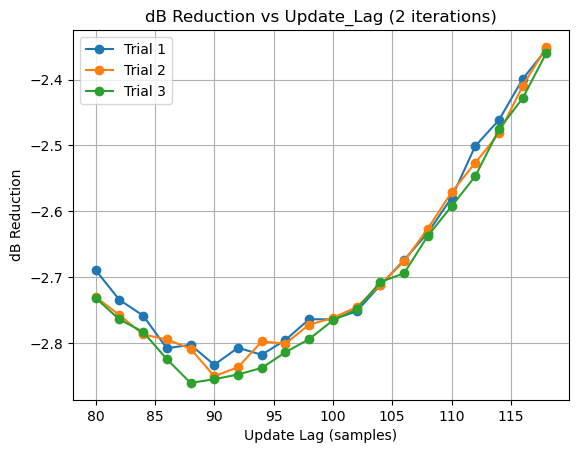

In [10]:
plot_lag_sweep(
    lags=data['normal_setup']['lags'],
    db_redux=data['normal_setup']['lag_sweep'],
    iters=data['normal_setup']['lag_iters']
)

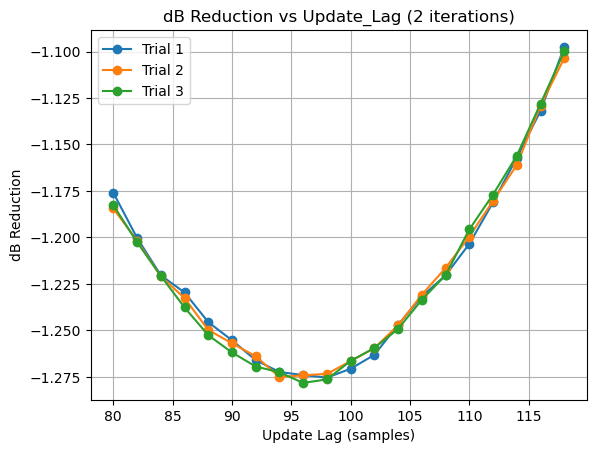

In [11]:
plot_lag_sweep(
    lags=data['horiz_angled_panel']['lags'],
    db_redux=data['horiz_angled_panel']['lag_sweep'],
    iters=data['horiz_angled_panel']['lag_iters']
)

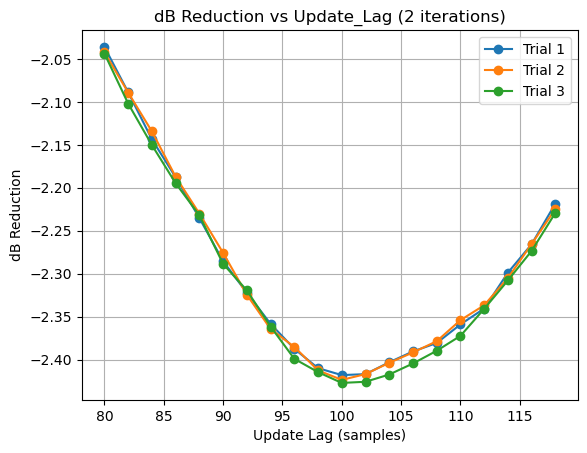

In [12]:
plot_lag_sweep(
    lags=data['horiz_angled_speaker']['lags'],
    db_redux=data['horiz_angled_speaker']['lag_sweep'],
    iters=data['horiz_angled_speaker']['lag_iters']
)

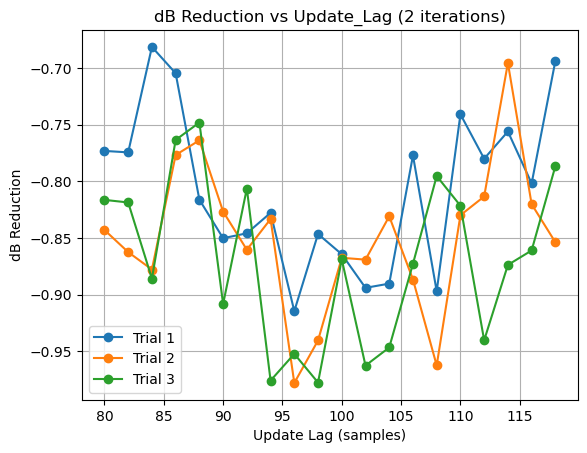

In [14]:
plot_lag_sweep(
    lags=data['speaker_direct']['lags'],
    db_redux=data['speaker_direct']['lag_sweep'],
    iters=data['speaker_direct']['lag_iters']
)

-3.5931711


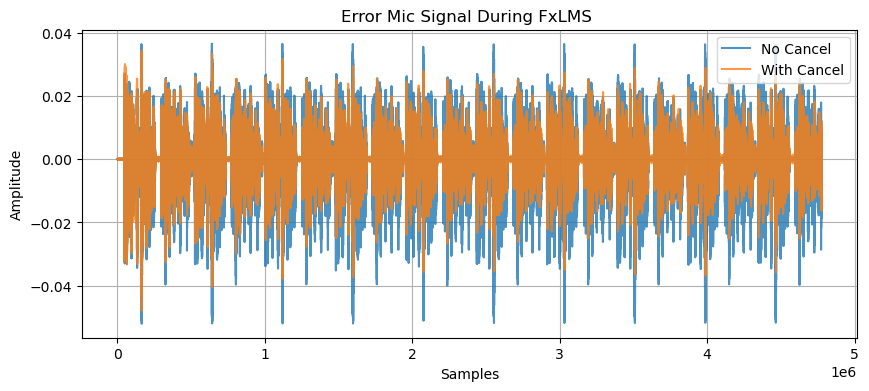

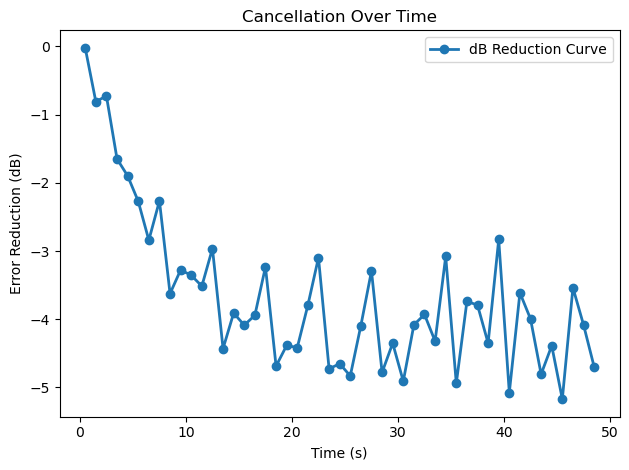

In [25]:
print(reduction_db(
    data['normal_setup']['error'],
    data['horiz_angled_speaker']['error_nc'],))
plot_error_mic(
    data['normal_setup']['error'],
    data['horiz_angled_speaker']['error_nc'],
)
plot_loss_curve(
    data['normal_setup']['error'],
    data['horiz_angled_speaker']['error_nc'],)

-1.9662081


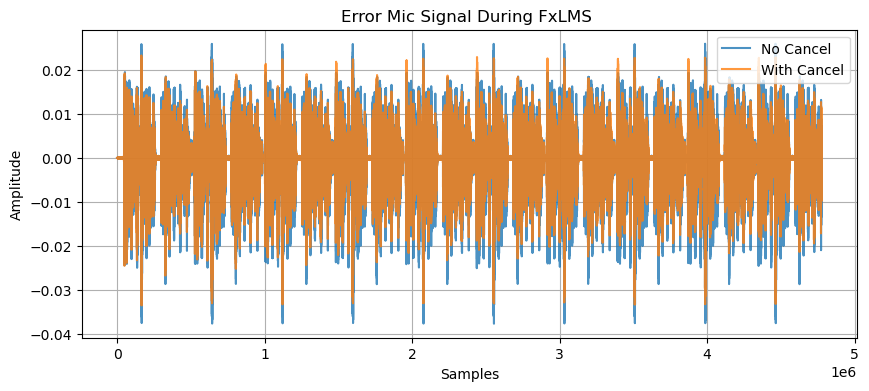

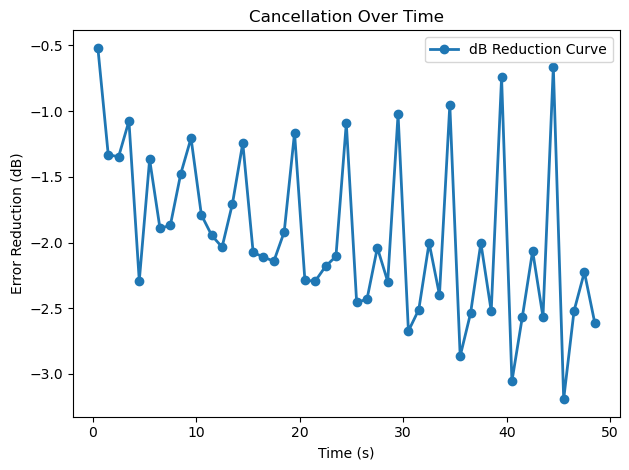

In [26]:
print(reduction_db(
    data['horiz_angled_panel']['error'],
    data['horiz_angled_panel']['error_nc'],
))
plot_error_mic(
    data['horiz_angled_panel']['error'],
    data['horiz_angled_panel']['error_nc'],
)
plot_loss_curve(
    data['horiz_angled_panel']['error'],
    data['horiz_angled_panel']['error_nc'],)

-6.4946117


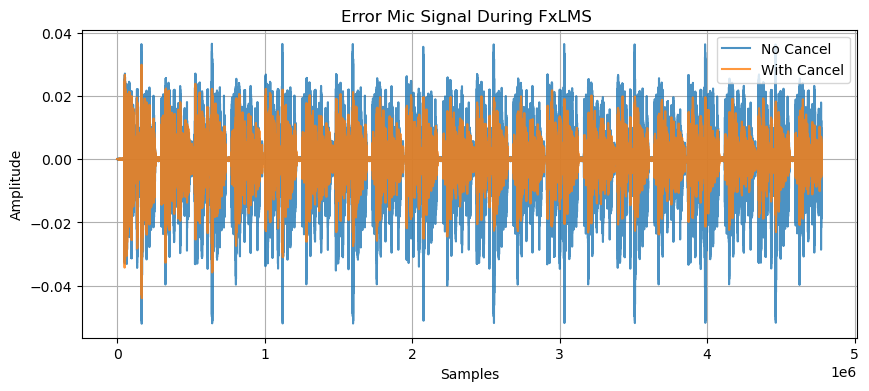

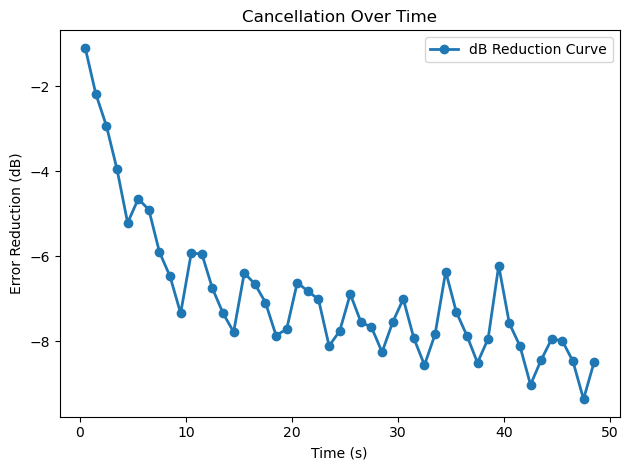

In [27]:
print(reduction_db(
    data['horiz_angled_speaker']['error'],
    data['horiz_angled_speaker']['error_nc'],
))
plot_error_mic(
    data['horiz_angled_speaker']['error'],
    data['horiz_angled_speaker']['error_nc'],
)
plot_loss_curve(
    data['horiz_angled_speaker']['error'],
    data['horiz_angled_speaker']['error_nc'],)

-0.46622175


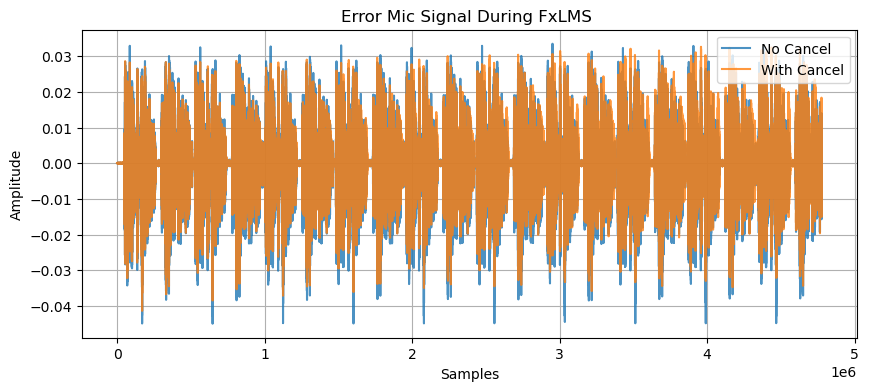

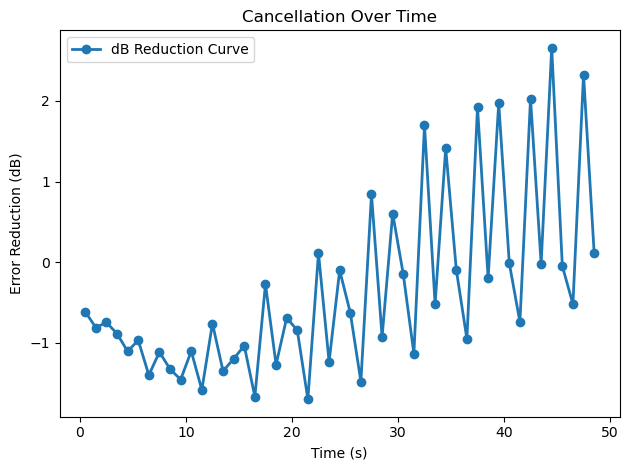

In [28]:
print(reduction_db(
    data['speaker_direct']['error'],
    data['speaker_direct']['error_nc'],
))
plot_error_mic(
    data['speaker_direct']['error'],
    data['speaker_direct']['error_nc'],
)
plot_loss_curve(
    data['speaker_direct']['error'],
    data['speaker_direct']['error_nc'],)